# Fase 4 – Modelado analítico
## 1. Clustering de días operativos 

In [1]:
# =============================================================
# FASE 4 - MODELADO ANALÍTICO
# Celda 1: Librerías, semilla, rutas y datos
# =============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# scikit-learn: la librería estándar de machine learning en Python
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEED = 42                 # misma semilla de todo el proyecto (reproducibilidad)
np.random.seed(SEED)

BASE_DIR = Path("..")
PROCESSED_DIR = BASE_DIR / "data" / "processed"
FIG_DIR = BASE_DIR / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

COLOR_TEXTO = "#52514e"
sns.set_theme(style="whitegrid", rc={
    "grid.color": "#e6e5e1", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": COLOR_TEXTO, "xtick.color": COLOR_TEXTO, "ytick.color": COLOR_TEXTO,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
})

# Capa plata (intervalos de 15 min) y capa oro (un registro por día)
df = pd.read_csv(PROCESSED_DIR / "steel_limpio.csv", parse_dates=["fecha_hora", "fecha"])
kpi = pd.read_csv(PROCESSED_DIR / "kpi_diario.csv", parse_dates=["fecha"])
print("Intervalos:", df.shape, "| Días:", kpi.shape)

Intervalos: (35040, 26) | Días: (365, 11)


In [2]:
# =============================================================
# Celda 2: Selección de variables y estandarización
# =============================================================
# ¿Por qué agrupar DÍAS y no intervalos de 15 minutos?
# Porque un jefe de planta decide por jornada (turnos, mantenimiento),
# y la capa oro ya resume cada día en una fila.
#
# Variables elegidas (una por cada dimensión del problema):
#   consumo_kwh                → cuánto produce la planta ese día
#   demanda_max_kw             → qué tan alto fue el pico
#   factor_carga               → qué tan pareja fue la curva
#   pct_intervalos_penalizados → qué tan mala fue la calidad eléctrica
# Dejamos fuera co2 y costo porque son casi copias del consumo (Gráfico 2),
# y "intervalos_carga_maxima" porque deriva de la etiqueta que predeciremos.
vars_cluster = ["consumo_kwh", "demanda_max_kw", "factor_carga", "pct_intervalos_penalizados"]
print(kpi[vars_cluster].describe().round(1))

# ESTANDARIZAR es obligatorio en K-means: el algoritmo mide distancias,
# y sin escalar el consumo (miles de kWh) aplastaría al factor de carga (0 a 1).
# StandardScaler deja cada variable con media 0 y desviación 1.
escalador = StandardScaler()
X_dias = escalador.fit_transform(kpi[vars_cluster])

       consumo_kwh  demanda_max_kw  factor_carga  pct_intervalos_penalizados
count        365.0           365.0         365.0                       365.0
mean        2629.2           343.3           0.4                        53.3
std         1480.2           179.2           0.2                        11.2
min          259.5            13.2           0.1                        28.1
25%         1575.6           244.4           0.3                        44.8
50%         2750.1           393.4           0.3                        50.0
75%         3529.9           486.7           0.4                        59.4
max         7353.8           628.7           0.9                        87.5


   k  inercia  silueta
0  2  744.436    0.559
1  3  500.385    0.389
2  4  307.029    0.449
3  5  247.711    0.409
4  6  214.522    0.377
5  7  188.679    0.383
6  8  163.357    0.392


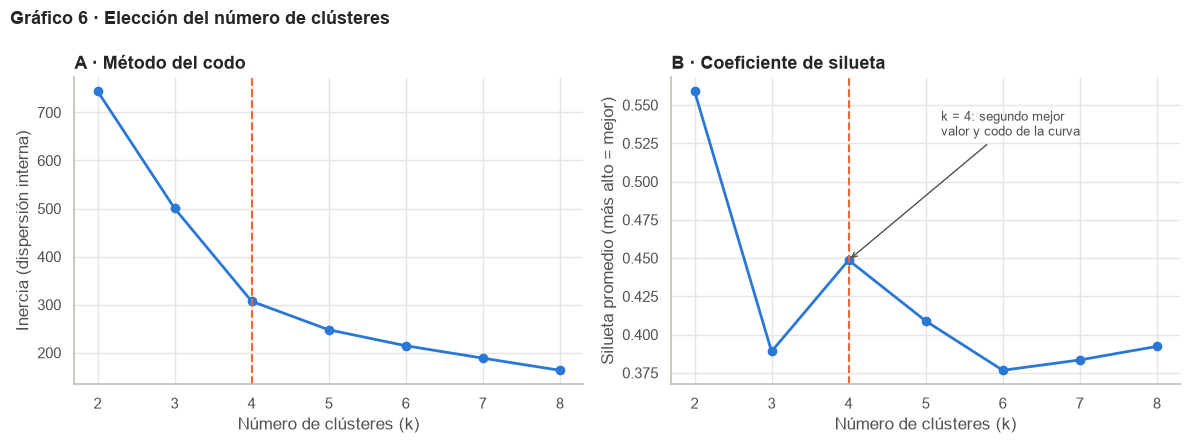

In [3]:
# =============================================================
# Celda 3: ¿Cuántos clústeres? Método del codo + silueta
# =============================================================
# Probamos k = 2 a 8 y guardamos dos métricas:
#  - Inercia: qué tan dispersos quedan los días dentro de su grupo.
#    Siempre baja al aumentar k; buscamos el "codo" donde deja de bajar mucho.
#  - Silueta (-1 a 1): qué tan bien separado está cada día de los otros grupos.
#    Más alto = grupos más nítidos.
resultados_k = []
for k in range(2, 9):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_dias)
    resultados_k.append({"k": k,
                         "inercia": modelo.inertia_,
                         "silueta": silhouette_score(X_dias, modelo.labels_)})
tabla_k = pd.DataFrame(resultados_k)
print(tabla_k.round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(tabla_k["k"], tabla_k["inercia"], marker="o", color="#2a78d6", linewidth=2)
ax1.set_title("A · Método del codo")
ax1.set_xlabel("Número de clústeres (k)")
ax1.set_ylabel("Inercia (dispersión interna)")
ax2.plot(tabla_k["k"], tabla_k["silueta"], marker="o", color="#2a78d6", linewidth=2)
ax2.set_title("B · Coeficiente de silueta")
ax2.set_xlabel("Número de clústeres (k)")
ax2.set_ylabel("Silueta promedio (más alto = mejor)")
for ax in (ax1, ax2):
    ax.axvline(4, color="#eb6834", linestyle="--", linewidth=1.5)   # k elegido
    ax.set_xticks(range(2, 9))
ax2.annotate("k = 4: segundo mejor\nvalor y codo de la curva",
             xy=(4, tabla_k.loc[tabla_k["k"] == 4, "silueta"].item()),
             xytext=(5.2, 0.53), fontsize=9, color=COLOR_TEXTO,
             arrowprops=dict(arrowstyle="->", color=COLOR_TEXTO))
fig.suptitle("Gráfico 6 · Elección del número de clústeres",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "g6_eleccion_k.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
# =============================================================
# Celda 4: K-means con k = 4 y perfil de cada clúster
# =============================================================
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X_dias)
kpi["cluster_id"] = kmeans.labels_

# K-means numera los grupos al azar (0, 1, 2, 3). Para que los nombres
# sean siempre los mismos, ordenamos los clústeres por consumo promedio
# y les asignamos un nombre de negocio en ese orden.
orden_consumo = kpi.groupby("cluster_id")["consumo_kwh"].mean().sort_values().index
nombres = ["Sin producción", "Producción reducida",
           "Producción con FP deteriorado", "Producción plena"]
mapa_nombres = dict(zip(orden_consumo, nombres))
kpi["perfil"] = pd.Categorical(kpi["cluster_id"].map(mapa_nombres),
                               categories=nombres, ordered=True)

# Perfil con las variables ORIGINALES (no las estandarizadas),
# porque son las que entiende un jefe de planta
perfil = kpi.groupby("perfil", observed=True).agg(
    dias=("fecha", "size"),
    consumo_kwh=("consumo_kwh", "mean"),
    demanda_max_kw=("demanda_max_kw", "mean"),
    factor_carga=("factor_carga", "mean"),
    pct_penalizado=("pct_intervalos_penalizados", "mean"),
    costo_penal_dia_usd=("costo_penalizacion_usd", "mean"),
    costo_penal_anual_usd=("costo_penalizacion_usd", "sum"),
    pct_fin_de_semana=("tipo_dia", lambda s: (s == "Weekend").mean() * 100),
)
perfil["% del costo de penalización"] = (perfil["costo_penal_anual_usd"]
                                         / perfil["costo_penal_anual_usd"].sum() * 100)
perfil.round(1)

,dias,consumo_kwh,demanda_max_kw,factor_carga,pct_penalizado,costo_penal_dia_usd,costo_penal_anual_usd,pct_fin_de_semana,% del costo de penalización
perfil,,,,,,,,,
Sin producción,57,379.7,22.3,0.7,43.9,11.9,679.3,78.9,8.4
Producción reducida,99,1837.4,283.9,0.3,47.4,16.7,1652.7,52.5,20.4
Producción con FP deteriorado,89,2999.8,409.2,0.3,70.0,35.2,3128.5,1.1,38.7
Producción plena,120,4076.0,496.0,0.3,50.3,21.9,2631.8,5.0,32.5


In [5]:
# =============================================================
# Celda 5: Validación de los perfiles con información externa
# =============================================================
# 1) Factor de potencia promedio de cada perfil (variable NO usada en el clustering)
fp_dia = df.groupby("fecha")["fp_atraso_pct"].mean()
kpi["fp_atraso_prom"] = kpi["fecha"].map(fp_dia)
print("FP en atraso promedio por perfil:")
print(kpi.groupby("perfil", observed=True)["fp_atraso_prom"].mean().round(1))

# 2) ¿En qué meses aparece cada perfil?
print("\nDías de cada perfil por mes:")
print(pd.crosstab(kpi["fecha"].dt.month, kpi["perfil"]))

# 3) ¿Dónde cayeron los 12 feriados detectados en el EDA (Gráfico 4)?
feriados = pd.to_datetime(["2018-01-01", "2018-02-15", "2018-02-16", "2018-05-01",
                           "2018-08-01", "2018-08-02", "2018-08-03", "2018-09-24",
                           "2018-09-25", "2018-09-26", "2018-12-25", "2018-12-31"])
print("\nPerfil de los 12 feriados:")
print(kpi.loc[kpi["fecha"].isin(feriados), "perfil"].value_counts())

FP en atraso promedio por perfil:
perfil
Sin producción                   82.0
Producción reducida              82.2
Producción con FP deteriorado    75.2
Producción plena                 82.6
Name: fp_atraso_prom, dtype: float64

Días de cada perfil por mes:
perfil  Sin producción  Producción reducida  Producción con FP deteriorado  \
fecha                                                                        
1                    3                    4                              0   
2                    6                    4                              0   
3                    4                   11                              1   
4                    3                   12                              5   
5                    5                    7                              9   
6                    4                   14                              7   
7                    2                   13                              3   
8                    9                

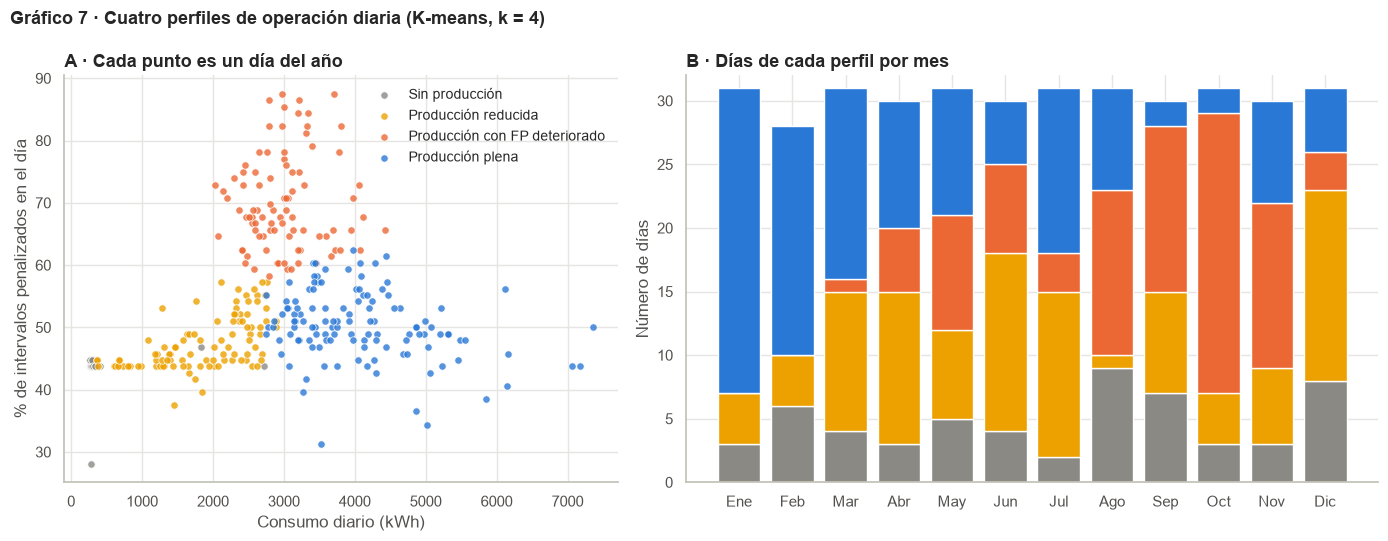

In [6]:
# =============================================================
# Celda 6: GRÁFICO 7 - Perfiles de operación diaria
# =============================================================
# Gris = sin producción (inactivo). Naranja = el perfil problemático,
# el mismo color de "alerta" que usamos en la presentación.
COLORES_PERFIL = {"Sin producción": "#8a8984",
                  "Producción reducida": "#eda100",
                  "Producción con FP deteriorado": "#eb6834",
                  "Producción plena": "#2a78d6"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5),
                               gridspec_kw={"width_ratios": [1, 1.25]})

# Panel A: cada día del año ubicado por consumo y % de penalización
for nombre in nombres:
    d = kpi[kpi["perfil"] == nombre]
    ax1.scatter(d["consumo_kwh"], d["pct_intervalos_penalizados"], s=28, alpha=0.8,
                color=COLORES_PERFIL[nombre], edgecolor="white", linewidth=0.6, label=nombre)
ax1.set_xlabel("Consumo diario (kWh)")
ax1.set_ylabel("% de intervalos penalizados en el día")
ax1.set_title("A · Cada punto es un día del año")
ax1.legend(frameon=False, loc="upper right", fontsize=10)

# Panel B: cuántos días de cada perfil hubo en cada mes (barras apiladas)
mes = pd.crosstab(kpi["fecha"].dt.month, kpi["perfil"])
base = np.zeros(12)
for nombre in nombres:
    ax2.bar(mes.index, mes[nombre], bottom=base, color=COLORES_PERFIL[nombre],
            width=0.8, edgecolor="white", linewidth=1)
    base += mes[nombre].values
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                     "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax2.set_ylabel("Número de días")
ax2.set_ylim(0, 32)
ax2.set_title("B · Días de cada perfil por mes")

fig.suptitle("Gráfico 7 · Cuatro perfiles de operación diaria (K-means, k = 4)",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "g7_perfiles_dias.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# =============================================================
# Celda 7: ¿Los clústeres son estables o salieron por casualidad?
# =============================================================
# ARI (Adjusted Rand Index): compara dos agrupaciones.
#   1 = idénticas | 0 = coinciden como si fuera al azar
# Prueba 1: repetir K-means con otras semillas
semillas = [1, 7, 123, 2024]
ari_semillas = [adjusted_rand_score(
                    kmeans.labels_,
                    KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(X_dias))
                for s in semillas]
print("ARI con otras semillas:", np.round(ari_semillas, 3))

# Prueba 2: comparar con otro algoritmo (clustering jerárquico de Ward)
jerarquico = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_dias)
print("ARI vs. jerárquico (Ward):", round(adjusted_rand_score(kmeans.labels_, jerarquico), 3))
print(pd.crosstab(kpi["perfil"], jerarquico))

# Guardamos los perfiles para el dashboard de la Fase 5
kpi.to_csv(PROCESSED_DIR / "kpi_diario_clusters.csv", index=False)

ARI con otras semillas: [1. 1. 1. 1.]
ARI vs. jerárquico (Ward): 0.68
col_0                           0   1   2   3
perfil                                       
Sin producción                  0   0   0  57
Producción reducida            99   0   0   0
Producción con FP deteriorado   2  67  20   0
Producción plena               24   0  96   0
